# Pathological cases

Situations where the obstacle sits right on top of the best region, on one simple function so that only the obstacle changes from case to case.

| case | obstacle | what to look at |
|---|---|---|
| A | a constraint cuts off the global optimum | the hatched infeasible region; the gap between the global optimum and the best feasible value |
| B | the feasible region is a tiny island (2% of the box) | how many evaluations the loop needs to find a feasible point (the acquisition is PoF only until then) |
| C | the DM rejects everything near the global optimum | the learned Copeland score at the optimum; where log EI and log EI + log Copeland sample |
| D | the DM only likes a corner where f is poor | the same, for the opposite conflict |
| E | none of the first 10 designs is feasible | what the optimiser returns before it has seen a feasible point |

The runs are saved to `runs/pathological_cases/results.pt` the first time and loaded from there afterwards (set `RERUN = True` to run them again).

In [10]:
import sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

for folder in (Path.cwd(), Path.cwd().parent):          # find the package next to or above this notebook
    if (folder / "BOproj").is_dir():
        sys.path.insert(0, str(folder))
        break

from BOproj.benchmarks import PairwiseLabeler
from BOproj.bo_loop import BayesianOptimizer, initial_design

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12})

## The function and the obstacles

$f$ is **maximised**: a narrow high peak (height 1) and a broad lower peak (height 0.6) on $[0, 1]^2$. Constraints are feasible where $c(x) \le 0$; a decision maker accepts a design where $u(x) > 0$ and answers comparisons without noise.

In [11]:
BOUNDS = [[0.0, 1.0], [0.0, 1.0]]
HIGH_PEAK, LOW_PEAK = np.array([0.78, 0.75]), np.array([0.28, 0.30])
ISLAND_CENTRE, ISLAND_RADIUS = np.array([0.55, 0.90]), 0.08
LIKED_CORNER = np.array([0.12, 0.88])


def two_peaks(X):
    # maximised: a narrow high peak (height 1) at HIGH_PEAK and a broad lower peak (height 0.6) at LOW_PEAK
    X = np.atleast_2d(X)
    high = np.exp(-np.sum((X - HIGH_PEAK) ** 2, axis=1) / (2 * 0.12 ** 2))
    low = 0.6 * np.exp(-np.sum((X - LOW_PEAK) ** 2, axis=1) / (2 * 0.22 ** 2))
    return high + low


def diagonal_cut(X):
    # case A, constraint: feasible where x1 + x2 <= 1.2, which cuts off the high peak
    X = np.atleast_2d(X)
    return X[:, 0] + X[:, 1] - 1.2


def small_island(X):
    # case B, constraint: feasible only inside a disc of radius 0.08 around ISLAND_CENTRE (2% of the box)
    X = np.atleast_2d(X)
    return np.sum((X - ISLAND_CENTRE) ** 2, axis=1) - ISLAND_RADIUS ** 2


def dislikes_the_optimum(X):
    # case C, DM utility: rejects (u < 0) every design within 0.3 of the high peak
    X = np.atleast_2d(X)
    return np.linalg.norm(X - HIGH_PEAK, axis=1) - 0.3


def likes_a_poor_corner(X):
    # case D, DM utility: accepts (u > 0) only a disc of radius 0.25 around LIKED_CORNER, where f is low
    X = np.atleast_2d(X)
    return 0.25 - np.linalg.norm(X - LIKED_CORNER, axis=1)


# the true answers, on a fine grid
grid_1, grid_2 = np.meshgrid(np.linspace(0, 1, 401), np.linspace(0, 1, 401))
X_GRID = np.c_[grid_1.ravel(), grid_2.ravel()]
F_GRID = two_peaks(X_GRID)


def best_on_grid(allowed=None):
    # (x, f) of the best grid design, among the allowed ones if a mask is given
    values = F_GRID if allowed is None else np.where(allowed, F_GRID, -np.inf)
    i = np.argmax(values)
    return X_GRID[i], values[i]


GLOBAL_X, GLOBAL_F = best_on_grid()
TARGETS = {"cut off": best_on_grid(diagonal_cut(X_GRID) <= 0),
           "island": best_on_grid(small_island(X_GRID) <= 0),
           "dislikes": best_on_grid(dislikes_the_optimum(X_GRID) > 0),
           "corner": best_on_grid(likes_a_poor_corner(X_GRID) > 0)}
print(f"global optimum: f = {GLOBAL_F:.3f} at {np.round(GLOBAL_X, 3)}")
for name, (x, f) in TARGETS.items():
    print(f"best allowed in case '{name}': f = {f:.3f} at {np.round(x, 3)}")


# case E, constraint: feasible only in a disc placed in the biggest empty spot among the 10 initial designs, so that none of them is feasible
NO_FEASIBLE_N_INIT, NO_FEASIBLE_SEED = 10, 0
START_POINTS = initial_design(BOUNDS, NO_FEASIBLE_N_INIT, "sobol", seed=NO_FEASIBLE_SEED)    # what BayesianOptimizer evaluates first with this n_init and seed
distance_to_start = np.min(np.linalg.norm(X_GRID[:, None, :] - START_POINTS[None, :, :], axis=2), axis=1)
interior = np.all((X_GRID > 0.1) & (X_GRID < 0.9), axis=1)                                  # keep the disc inside the box
emptiest = np.argmax(np.where(interior, distance_to_start, -np.inf))
FEASIBLE_CENTRE, FEASIBLE_RADIUS = X_GRID[emptiest], 0.8 * distance_to_start[emptiest]


def no_feasible_start(X):
    X = np.atleast_2d(X)
    return np.sum((X - FEASIBLE_CENTRE) ** 2, axis=1) - FEASIBLE_RADIUS ** 2


assert np.all(no_feasible_start(START_POINTS) > 0), "the initial design must be infeasible"
TARGETS["no feasible start"] = best_on_grid(no_feasible_start(X_GRID) <= 0)
print(f"case 'no feasible start': feasible disc of radius {FEASIBLE_RADIUS:.3f} around {np.round(FEASIBLE_CENTRE, 3)} "
      f"({np.mean(no_feasible_start(X_GRID) <= 0):.1%} of the box); best allowed f = {TARGETS['no feasible start'][1]:.3f}")

global optimum: f = 1.006 at [0.78 0.75]
best allowed in case 'cut off': f = 0.600 at [0.28 0.3 ]
best allowed in case 'island': f = 0.275 at [0.618 0.858]
best allowed in case 'dislikes': f = 0.600 at [0.28 0.3 ]
best allowed in case 'corner': f = 0.167 at [0.18  0.638]
case 'no feasible start': feasible disc of radius 0.234 around [0.103 0.103] (10.0% of the box); best allowed f = 0.594


## The runs

Six runs, same seed, 20 BO steps each (the initial design has 6 Sobol points, except in case E where it has 10):
- a reference without constraint or DM (it is also the "log EI" run of cases C and D: the DM does not change it);
- case A and case B: constrained log EI;
- case E: constrained log EI with a constraint that every one of the 10 initial designs violates;
- case C and case D: log EI + log Copeland, the DM compares 30 random pairs of 30 designs before the start.

In [3]:
N_BO_STEPS, SEED = 20, 0
assert SEED == NO_FEASIBLE_SEED                           # case E's constraint was built for this seed
X_PREF = initial_design(BOUNDS, 30, "lhs", seed=7)       # the designs the DM is asked to compare
RESULTS_FILE = Path("runs") / "pathological_cases" / "results.pt"
RERUN = False                                             # True: run all the loops again even if saved runs exist


def run_case(constraints=(), utility=None, n_init=None):
    # one BO run on two_peaks; with a utility, a noise-free DM and the Copeland score in the acquisition
    if utility is None:
        optimizer = BayesianOptimizer(two_peaks, BOUNDS, constraints=constraints, n_init=n_init, seed=SEED)
    else:
        optimizer = BayesianOptimizer(two_peaks, BOUNDS, constraints=constraints, n_init=n_init, seed=SEED,
                                      comparer=PairwiseLabeler(utility), X_pref=X_PREF,
                                      preference_score="copeland", n_landmarks=64)
    return optimizer.run(N_BO_STEPS)


CASES = {"reference": lambda: run_case(),
         "cut off": lambda: run_case(constraints=[diagonal_cut]),
         "island": lambda: run_case(constraints=[small_island]),
         "dislikes": lambda: run_case(utility=dislikes_the_optimum),
         "corner": lambda: run_case(utility=likes_a_poor_corner),
         "no feasible start": lambda: run_case(constraints=[no_feasible_start], n_init=NO_FEASIBLE_N_INIT)}

runs = {} if RERUN or not RESULTS_FILE.exists() else torch.load(RESULTS_FILE, weights_only=False)
missing = [name for name in CASES if name not in runs]
for name in missing:
    runs[name] = CASES[name]()
if missing:
    RESULTS_FILE.parent.mkdir(parents=True, exist_ok=True)
    torch.save(runs, RESULTS_FILE)
print(f"runs computed: {missing or 'none'}; runs loaded from {RESULTS_FILE}: {[name for name in CASES if name not in missing]}")

runs computed: ['no feasible start']; runs loaded from runs/pathological_cases/results.pt: ['reference', 'cut off', 'island', 'dislikes', 'corner']


### Plot helpers

Maps use `plot_points` (evaluations over a background; yellow = high). On top of it: the global optimum (hollow red star), the best allowed design of the case (green star), the infeasible region (grey, hatched) and the region the DM rejects (hatched).

In [4]:
GLOBAL_STYLE = dict(marker="*", ms=24, mfc="none", mec="red", mew=2.4, linestyle="none")
TARGET_STYLE = dict(marker="*", ms=20, mfc="lime", mec="k", mew=1.2, linestyle="none")
LEGEND_BELOW = dict(fontsize=10, loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2, frameon=False)


def shade_infeasible(axis, constraint):
    # grey, hatched over the region the constraint forbids (c > 0)
    values = constraint(X_GRID).reshape(grid_1.shape)
    levels = [0, values.max() + 1]
    axis.contourf(grid_1, grid_2, values, levels=levels, colors=["0.45"], alpha=0.55)
    axis.contourf(grid_1, grid_2, values, levels=levels, colors="none", hatches=["//"])
    axis.fill_between([], [], color="0.45", alpha=0.55, hatch="//", label="infeasible (c > 0)")


def hatch_rejected(axis, utility):
    # hatching (no fill) over the region the DM rejects (u < 0)
    values = utility(X_GRID).reshape(grid_1.shape)
    axis.contourf(grid_1, grid_2, values, levels=[values.min() - 1, 0], colors="none", hatches=["\\\\"])
    axis.contour(grid_1, grid_2, values, levels=[0], colors="magenta", linestyles=":", linewidths=1.8)
    axis.fill_between([], [], facecolor="none", hatch="\\\\", label="the DM rejects (u < 0)")


def draw_map(axis, run, title, target, target_label, background=two_peaks, background_label="f(x)"):
    # evaluations over a background map, the global optimum and the case's best allowed design
    run.plot_points(ax=axis, background=background, background_label=background_label, cmap="viridis", step_colorbar=False)
    axis.plot(*GLOBAL_X, **GLOBAL_STYLE, label=f"global optimum: f = {GLOBAL_F:.2f}")
    axis.plot(*target[0], **TARGET_STYLE, label=f"{target_label}: f = {target[1]:.2f}")
    axis.set_title(title)


def finish(axis):
    axis.legend(**LEGEND_BELOW)

## A. The constraint cuts off the global optimum

$x_1 + x_2 \le 1.2$ forbids the high peak. The best feasible design is the low peak, so the best the loop can do is about 0.4 below the global optimum. Left: where the loop sampled. Right: every evaluation (blue feasible, red cross infeasible) and the best feasible value so far.

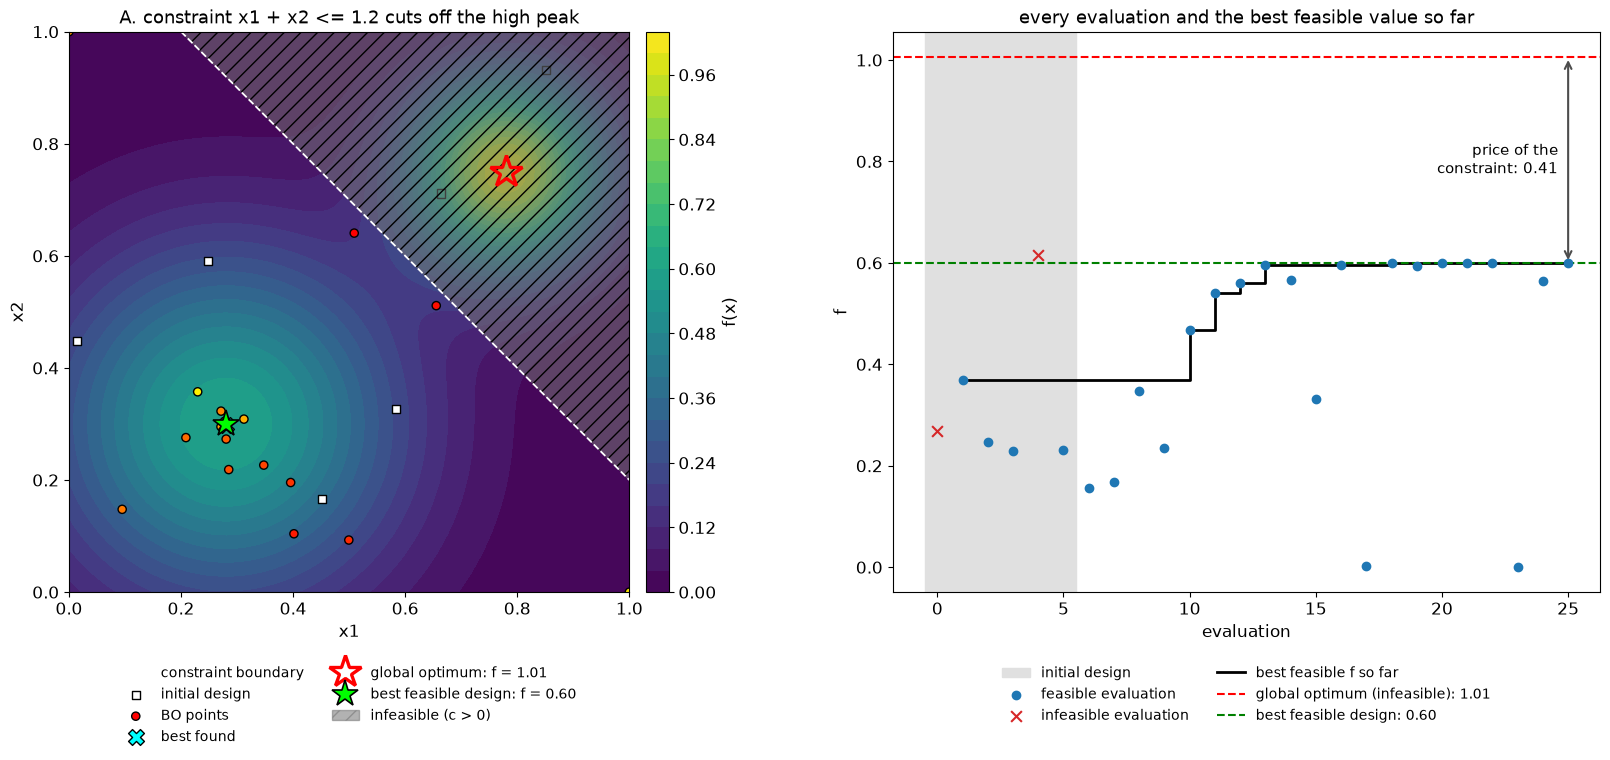

In [5]:
run, target = runs["cut off"], TARGETS["cut off"]
fig, (map_axis, trace_axis) = plt.subplots(1, 2, figsize=(17, 7.8))

draw_map(map_axis, run, "A. constraint x1 + x2 <= 1.2 cuts off the high peak", target, "best feasible design")
shade_infeasible(map_axis, diagonal_cut)
finish(map_axis)

evaluations = np.arange(len(run.y))
trace_axis.axvspan(-0.5, run.n_init - 0.5, color="0.88", label="initial design")
trace_axis.scatter(evaluations[run.feasible], run.y[run.feasible], color="tab:blue", zorder=3, label="feasible evaluation")
trace_axis.scatter(evaluations[~run.feasible], run.y[~run.feasible], marker="x", s=60, color="tab:red", zorder=3, label="infeasible evaluation")
trace_axis.step(evaluations, run.history("best_y"), where="post", color="k", lw=2, label="best feasible f so far")
trace_axis.axhline(GLOBAL_F, color="red", ls="--", label=f"global optimum (infeasible): {GLOBAL_F:.2f}")
trace_axis.axhline(target[1], color="green", ls="--", label=f"best feasible design: {target[1]:.2f}")
trace_axis.annotate("", xy=(len(run.y) - 1, GLOBAL_F), xytext=(len(run.y) - 1, target[1]),
                    arrowprops=dict(arrowstyle="<->", color="0.3", lw=1.5))
trace_axis.text(len(run.y) - 1.4, (GLOBAL_F + target[1]) / 2, f"price of the\nconstraint: {GLOBAL_F - target[1]:.2f}",
                ha="right", va="center", fontsize=11)
trace_axis.set(xlabel="evaluation", ylabel="f", title="every evaluation and the best feasible value so far")
finish(trace_axis)
plt.tight_layout()
plt.show()

## B. A tiny feasible island

Feasible only inside a disc of radius 0.08 (2% of the box), away from both peaks. Until the first feasible evaluation the incumbent does not exist, so the acquisition drops EI and maximises the probability of feasibility alone. Right: the model's PoF at each chosen point, before it is evaluated, and which evaluations turned out feasible.

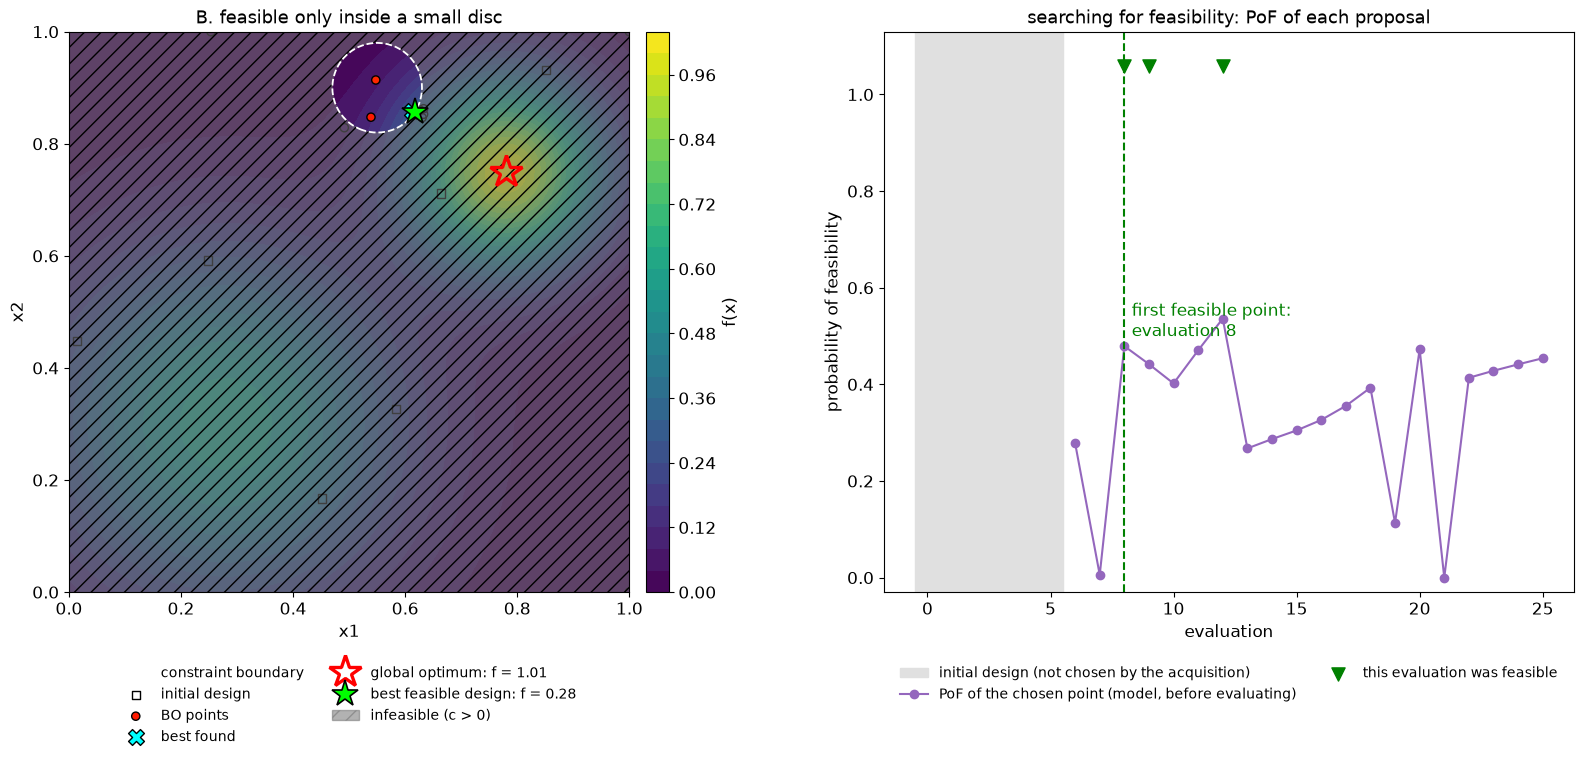

In [6]:
run, target = runs["island"], TARGETS["island"]
fig, (map_axis, pof_axis) = plt.subplots(1, 2, figsize=(17, 7.8))

draw_map(map_axis, run, "B. feasible only inside a small disc", target, "best feasible design")
shade_infeasible(map_axis, small_island)
finish(map_axis)

evaluations = np.arange(len(run.y))
pof_axis.axvspan(-0.5, run.n_init - 0.5, color="0.88", label="initial design (not chosen by the acquisition)")
pof_axis.plot(evaluations, run.history("pof"), "o-", color="tab:purple", label="PoF of the chosen point (model, before evaluating)")
pof_axis.scatter(evaluations[run.feasible], np.full(run.feasible.sum(), 1.06), marker="v", s=90, color="green",
                 label="this evaluation was feasible")
first_feasible = np.flatnonzero(run.feasible)
if len(first_feasible):
    pof_axis.axvline(first_feasible[0], color="green", ls="--")
    pof_axis.text(first_feasible[0] + 0.3, 0.5, f"first feasible point:\nevaluation {first_feasible[0]}", color="green", fontsize=12)
else:
    pof_axis.text(0.5, 0.5, "no feasible point found", transform=pof_axis.transAxes, ha="center", color="red", fontsize=14)
pof_axis.set(ylim=(-0.03, 1.13), xlabel="evaluation", ylabel="probability of feasibility",
             title="searching for feasibility: PoF of each proposal")
finish(pof_axis)
plt.tight_layout()
plt.show()

## C. The decision maker rejects the global optimum

The DM rejects every design within 0.3 of the high peak. Left: log EI, which ignores the DM. Right: log EI + log Copeland. The hatched disc is what the DM rejects.

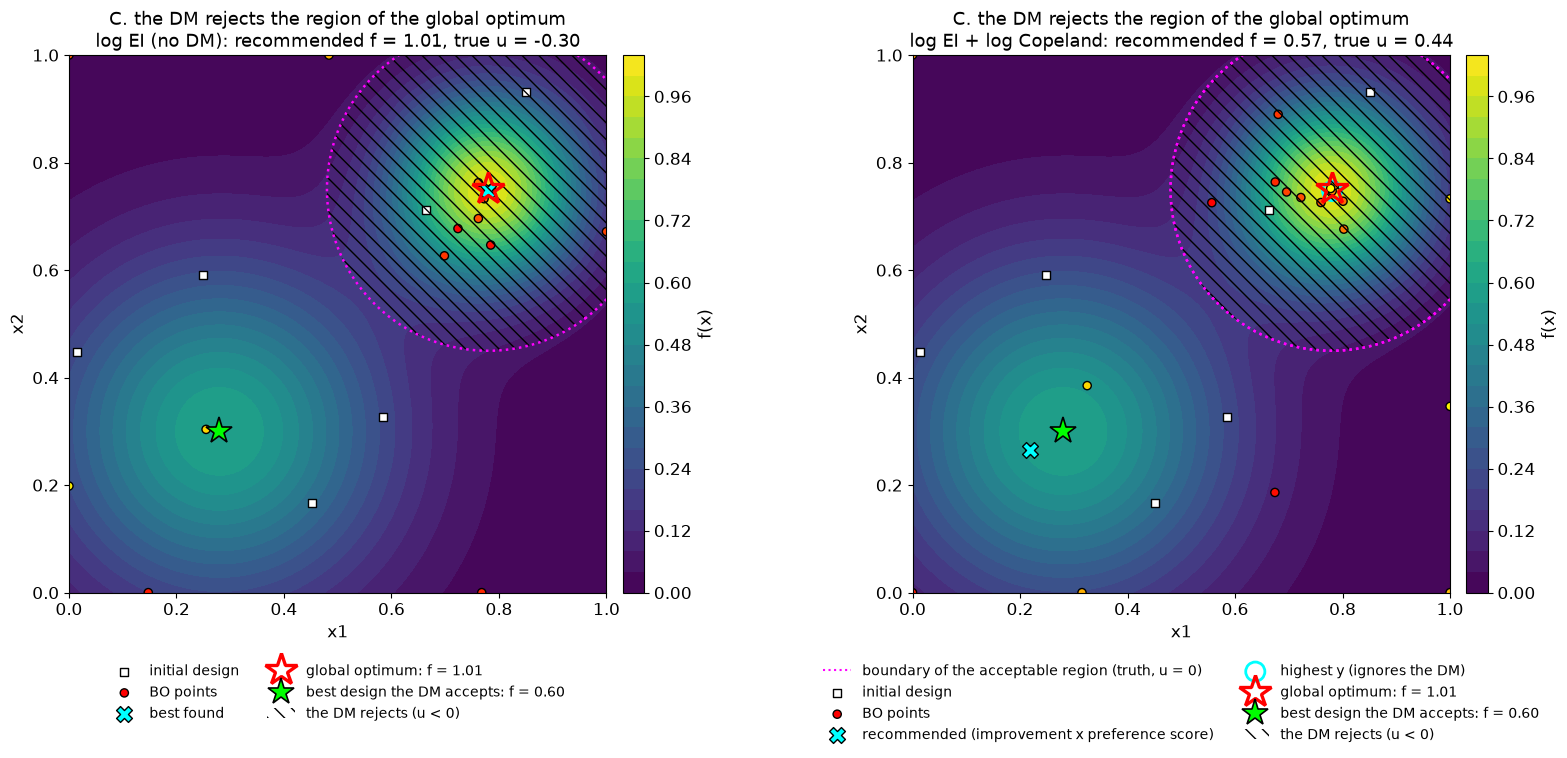

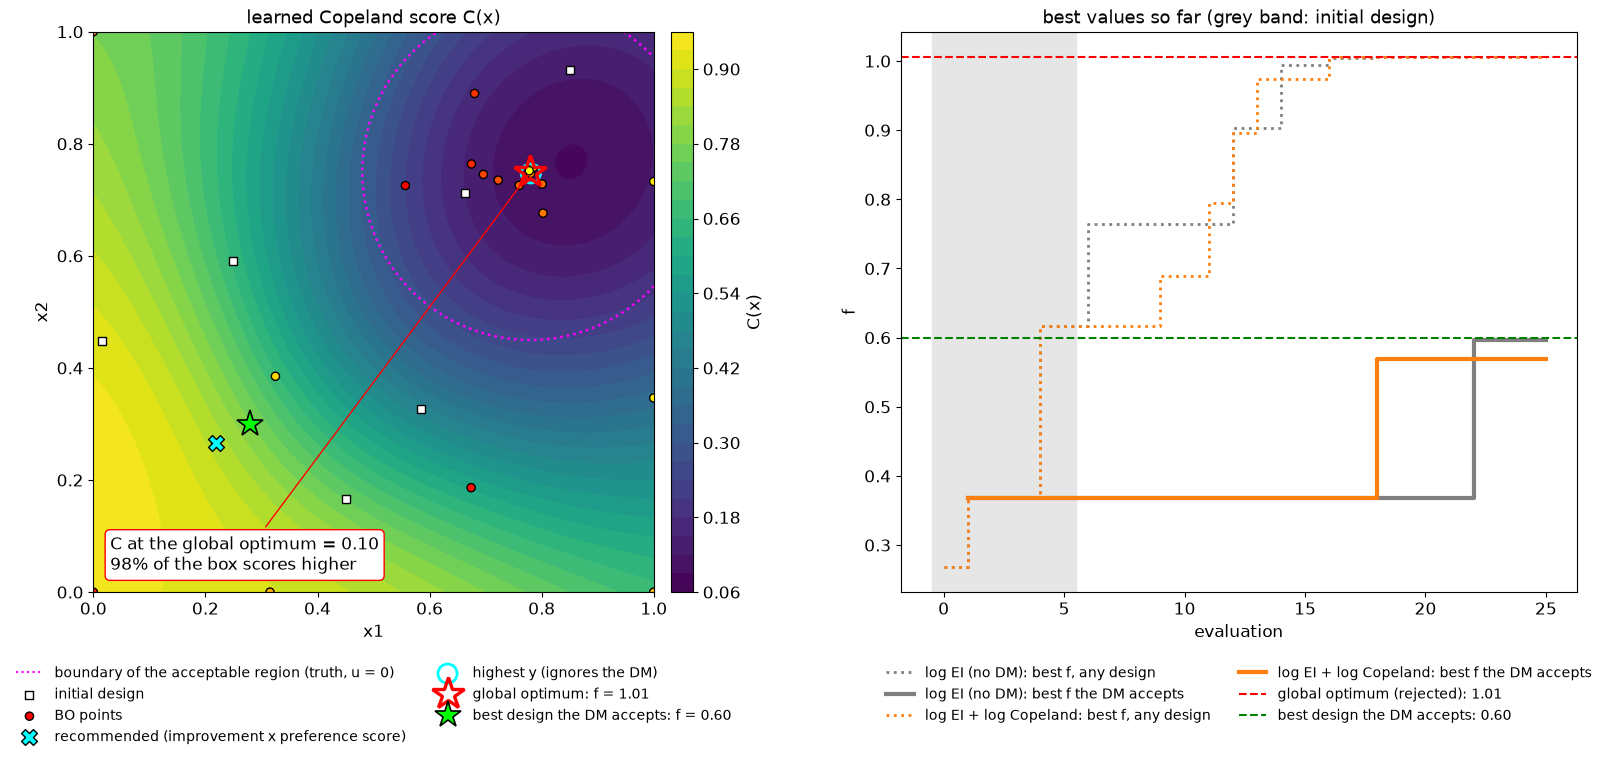

In [7]:
def show_dm_case(case, utility, title):
    # two figures: the two runs on f; then the learned Copeland map and the best values over the evaluations
    reference, copeland_run, target = runs["reference"], runs[case], TARGETS[case]

    fig, axes = plt.subplots(1, 2, figsize=(17, 7.8))
    for axis, (label, run) in zip(axes, (("log EI (no DM)", reference), ("log EI + log Copeland", copeland_run))):
        draw_map(axis, run, f"{title}\n{label}", target, "best design the DM accepts")
        hatch_rejected(axis, utility)
        recommended_x, recommended_y = run.recommended()
        axis.set_title(f"{title}\n{label}: recommended f = {recommended_y:.2f}, true u = {utility(recommended_x[None])[0]:.2f}")
        finish(axis)
    plt.tight_layout()
    plt.show()

    fig, (score_axis, trace_axis) = plt.subplots(1, 2, figsize=(17, 7.8))
    draw_map(score_axis, copeland_run, "learned Copeland score C(x)", target, "best design the DM accepts",
             background=copeland_run.preference_scores, background_label="C(x)")
    score_at_optimum = float(copeland_run.preference_scores(GLOBAL_X[None])[0])
    share_higher = float(np.mean(copeland_run.preference_scores(X_GRID[::7]) > score_at_optimum))
    score_axis.annotate(f"C at the global optimum = {score_at_optimum:.2f}\n{share_higher:.0%} of the box scores higher",
                        xy=GLOBAL_X, xytext=(0.03, 0.04), textcoords="axes fraction", fontsize=12,
                        bbox=dict(boxstyle="round", fc="white", ec="red"), arrowprops=dict(arrowstyle="->", color="red"))
    finish(score_axis)

    for (label, run), color in zip((("log EI (no DM)", reference), ("log EI + log Copeland", copeland_run)), ("tab:gray", "tab:orange")):
        evaluations = np.arange(len(run.y))
        accepted = utility(run.X) > 0
        best_any = np.maximum.accumulate(run.y)
        best_accepted = np.maximum.accumulate(np.where(accepted, run.y, -np.inf))
        trace_axis.step(evaluations, best_any, where="post", color=color, ls=":", lw=2, label=f"{label}: best f, any design")
        trace_axis.step(evaluations, np.where(np.isfinite(best_accepted), best_accepted, np.nan), where="post", color=color, lw=3,
                        label=f"{label}: best f the DM accepts")
    trace_axis.axvspan(-0.5, reference.n_init - 0.5, color="0.9")
    trace_axis.axhline(GLOBAL_F, color="red", ls="--", label=f"global optimum (rejected): {GLOBAL_F:.2f}")
    trace_axis.axhline(target[1], color="green", ls="--", label=f"best design the DM accepts: {target[1]:.2f}")
    trace_axis.set(xlabel="evaluation", ylabel="f", title="best values so far (grey band: initial design)")
    finish(trace_axis)
    plt.tight_layout()
    plt.show()


show_dm_case("dislikes", dislikes_the_optimum, "C. the DM rejects the region of the global optimum")

## D. The decision maker only likes a poor region

The DM accepts only a disc around $(0.12, 0.88)$, where $f$ is low everywhere (outside the disc is hatched). The best design it accepts is far below both peaks, and the Copeland score is highest exactly where f is poor.

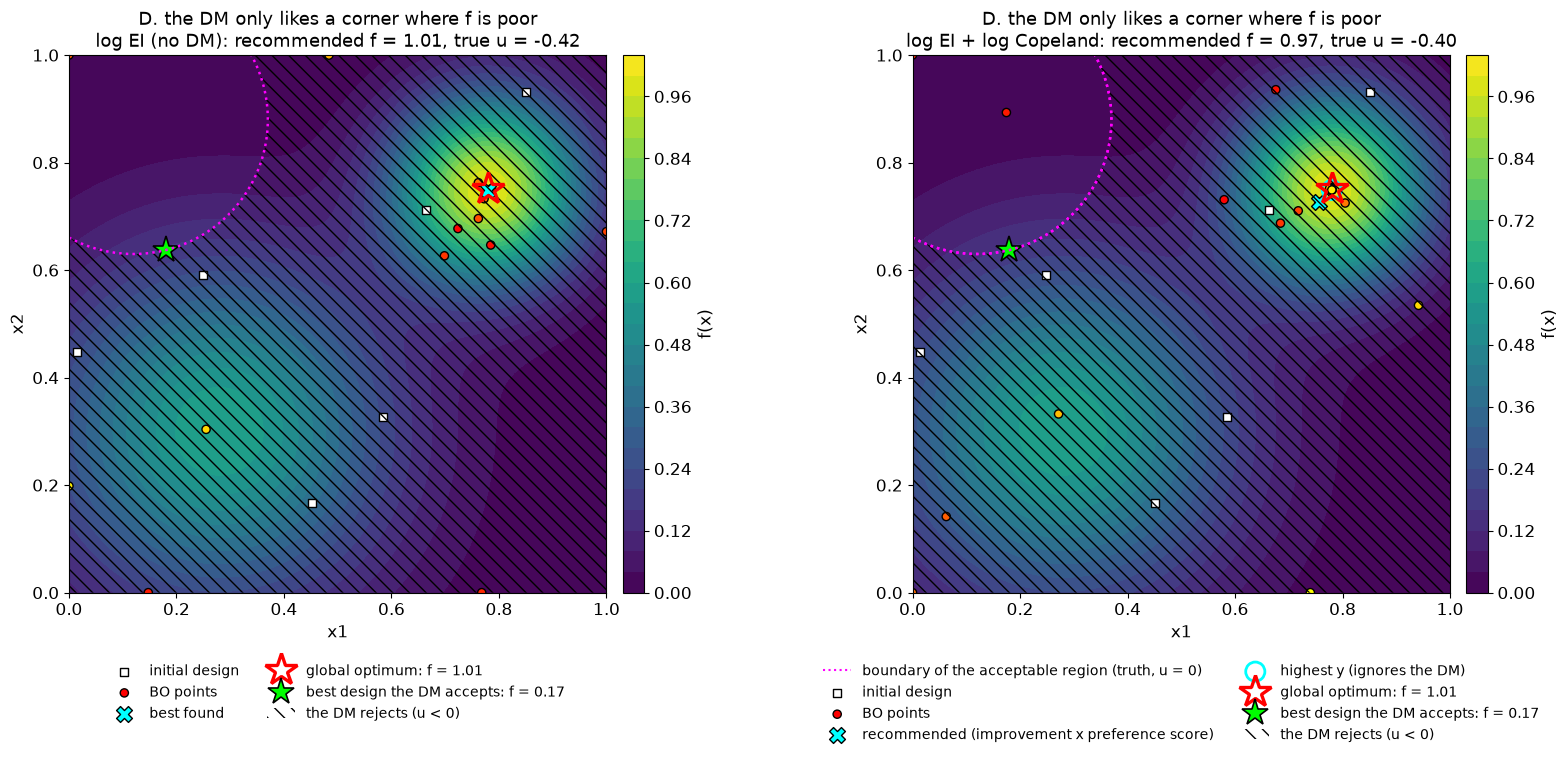

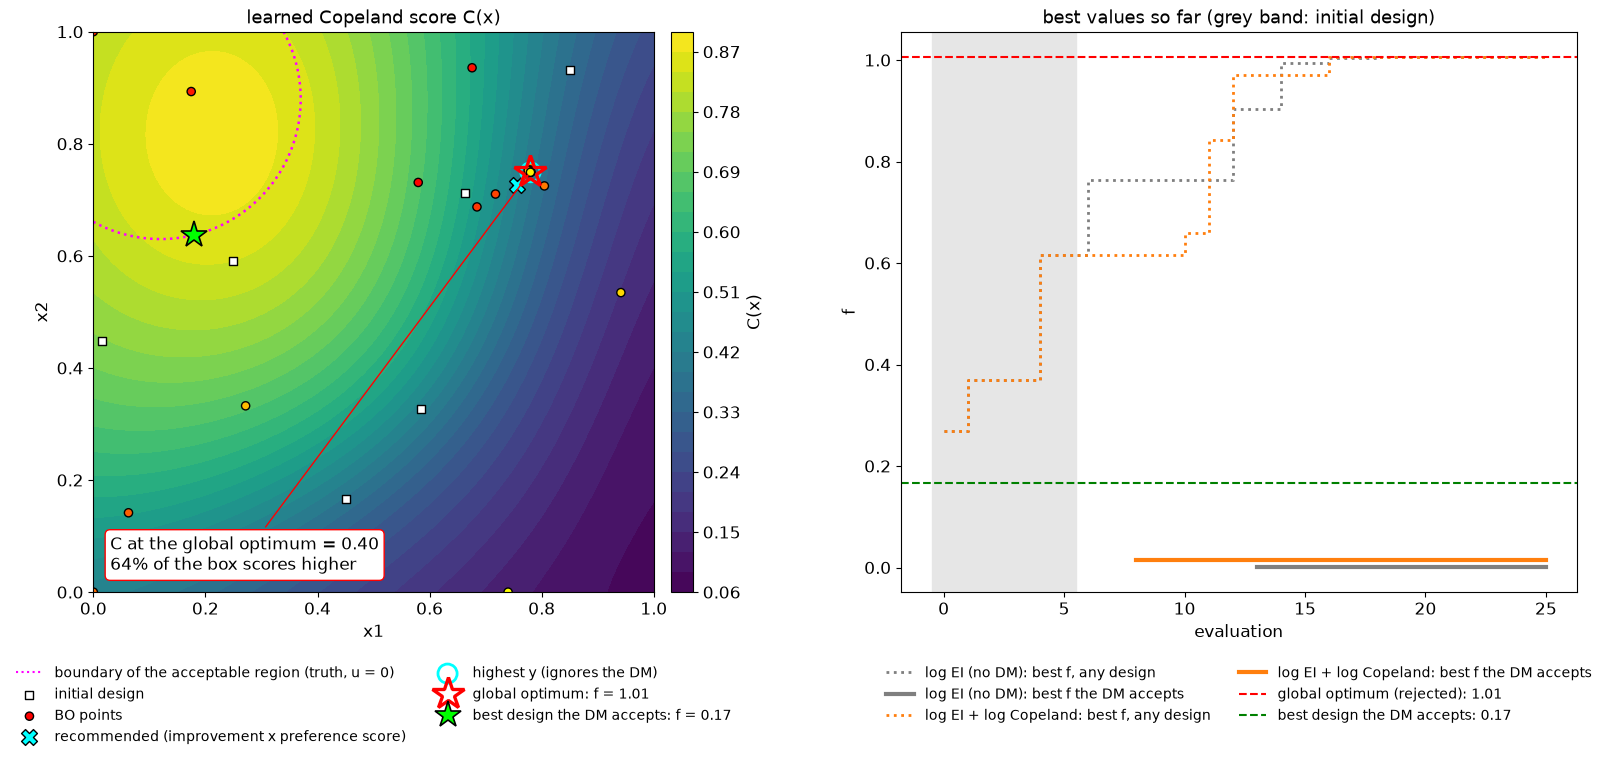

In [8]:
show_dm_case("corner", likes_a_poor_corner, "D. the DM only likes a corner where f is poor")

## E. None of the first 10 designs is feasible

The constraint is feasible only in a disc placed in the biggest empty spot among the 10 initial Sobol designs (the cell above asserts that none of them is feasible). `BayesianOptimizer` then starts with **no feasible observation**:
- `best()` has nothing to return: it gives `(None, nan)`, and so does `recommended()`, which falls back to it. The incumbent for EI does not exist.
- The acquisition drops EI and maximises the probability of feasibility alone. As soon as one evaluation is feasible, EI comes back with that incumbent.
- Every constraint is treated as a black box: it gets its own GP fitted on the evaluated designs, even when its formula is known.

The table shows these three things at each step, from the end of the initial design to two steps after the first feasible point.

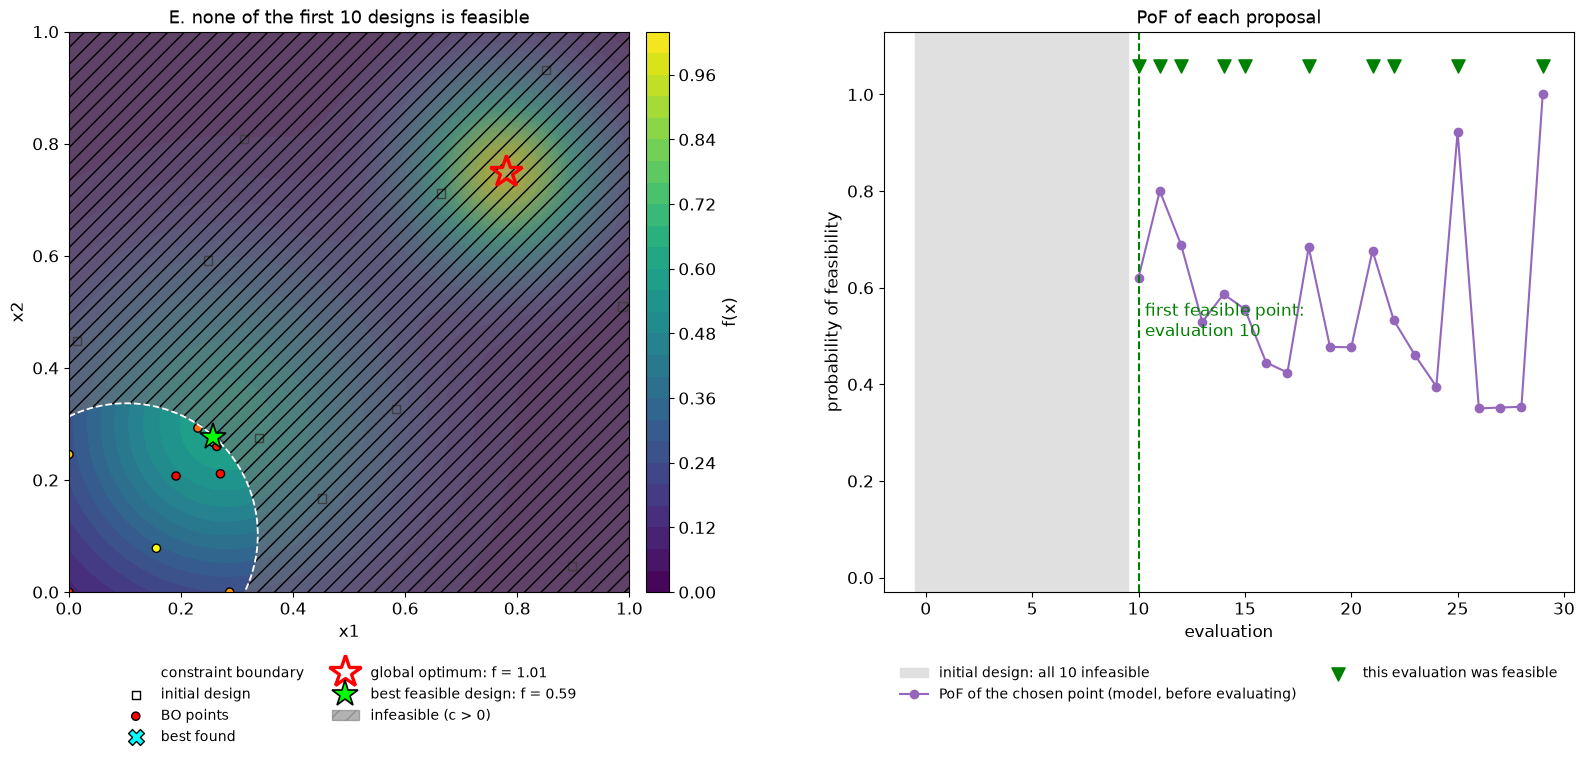

evaluations so far  feasible so far    run.best(n)   run.recommended(n)  EI in the acquisition  closest to feasible: c
                10                0           none                 none          no (PoF only)                   0.031
                11                1      y = 0.506            y = 0.506                    yes                  -0.036
                12                2      y = 0.552            y = 0.552                    yes                  -0.036


In [9]:
run, target = runs["no feasible start"], TARGETS["no feasible start"]
first_feasible = np.flatnonzero(run.feasible)
first_feasible = first_feasible[0] if len(first_feasible) else None
assert not run.feasible[:run.n_init].any()

fig, (map_axis, pof_axis) = plt.subplots(1, 2, figsize=(17, 7.8))
draw_map(map_axis, run, "E. none of the first 10 designs is feasible", target, "best feasible design")
shade_infeasible(map_axis, no_feasible_start)
finish(map_axis)

evaluations = np.arange(len(run.y))
pof_axis.axvspan(-0.5, run.n_init - 0.5, color="0.88", label=f"initial design: all {run.n_init} infeasible")
pof_axis.plot(evaluations, run.history("pof"), "o-", color="tab:purple", label="PoF of the chosen point (model, before evaluating)")
pof_axis.scatter(evaluations[run.feasible], np.full(run.feasible.sum(), 1.06), marker="v", s=90, color="green", label="this evaluation was feasible")
if first_feasible is not None:
    pof_axis.axvline(first_feasible, color="green", ls="--")
    pof_axis.text(first_feasible + 0.3, 0.5, f"first feasible point:\nevaluation {first_feasible}", color="green", fontsize=12)
pof_axis.set(ylim=(-0.03, 1.13), xlabel="evaluation", ylabel="probability of feasibility", title="PoF of each proposal")
finish(pof_axis)
plt.tight_layout()
plt.show()

print(f"{'evaluations so far':>18s} {'feasible so far':>16s} {'run.best(n)':>14s} {'run.recommended(n)':>20s} {'EI in the acquisition':>22s} {'closest to feasible: c':>23s}")
last_n = len(run.y) if first_feasible is None else min(first_feasible + 3, len(run.y))
for n in range(run.n_init, last_n):
    best_x, best_y = run.best(n)
    recommended_x, recommended_y = run.recommended(n)
    show = lambda x, y: "none" if x is None else f"y = {y:.3f}"
    print(f"{n:18d} {int(run.feasible[:n].sum()):16d} {show(best_x, best_y):>14s} {show(recommended_x, recommended_y):>20s} "
          f"{'yes' if run.acquisition(n).log_ei is not None else 'no (PoF only)':>22s} {run.C[:n, 0].min():23.3f}")

## Summary

For each run: the recommended design (`run.recommended()`; without a DM the same as `run.best()`), the best value the case allows, and the gap between them.

In [10]:
cases = (("reference", None, None, (GLOBAL_X, GLOBAL_F)),
         ("cut off", diagonal_cut, None, TARGETS["cut off"]),
         ("island", small_island, None, TARGETS["island"]),
         ("dislikes", None, dislikes_the_optimum, TARGETS["dislikes"]),
         ("corner", None, likes_a_poor_corner, TARGETS["corner"]),
         ("no feasible start", no_feasible_start, None, TARGETS["no feasible start"]))
print(f"{'case':10s} {'recommended f':>14s} {'best allowed f':>15s} {'gap':>7s} {'true u':>7s} {'first feasible eval':>20s} {'global f':>9s}")
for name, constraint, utility, (target_x, target_f) in cases:
    run = runs[name]
    recommended_x, recommended_y = run.recommended()
    first = np.flatnonzero(run.feasible)
    first_text = str(first[0]) if len(first) else "none"
    if recommended_x is None:
        print(f"{name:10s} {'none feasible':>14s} {target_f:15.3f} {'-':>7s} {'-':>7s} {first_text:>20s} {GLOBAL_F:9.3f}")
        continue
    u_text = "-" if utility is None else f"{utility(recommended_x[None])[0]:.2f}"
    print(f"{name:10s} {recommended_y:14.3f} {target_f:15.3f} {target_f - recommended_y:7.3f} {u_text:>7s} {first_text:>20s} {GLOBAL_F:9.3f}")

case        recommended f  best allowed f     gap  true u  first feasible eval  global f
reference           1.006           1.006  -0.000       -                    0     1.006
cut off             0.600           0.600   0.000       -                    1     1.006
island              0.261           0.275   0.014       -                    8     1.006
dislikes            0.570           0.600   0.030    0.44                    0     1.006
corner              0.970           0.167  -0.803   -0.40                    0     1.006
no feasible start          0.594           0.594  -0.000       -                   10     1.006
